# Hotel Booking Cancellation Prediction

## Dataset Overview
The data contains hotel bookings, guest details and planned stays. 'is_canceled' is '0' for 'not cancelled' and '1' for cancelled.

## Project Objective
I compare models to predict booking cancellations and use K-Means to explore groups of similar bookings.

This could help hotels plan room availability, staffing and expected income. The predictions can support planning, but some will be wrong.

Dataset: https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

# Importing Libraries
I import the libraries for working with data, charts and models.

In [85]:
# Importing Libraries
# os helps locate the CSV in the notebook folder or in data/.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report, silhouette_score

# Data Loading Class
This class loads the CSV. If it is missing, Colab asks for an upload. Run the cells in order.

In [86]:
# Data Loading Class
class DataLoader:
    # Store the starting data and settings for this object.
    def __init__(self, filename):
        self.filename = filename

    # Load the CSV from data/ or the notebook folder; ask for an upload in Colab.
    def load_data(self):
        candidates = [
            self.filename,
            "data/" + self.filename,
            self.filename.split("/")[-1]
        ]
        for path in candidates:
            if os.path.exists(path):
                self.df = pd.read_csv(path)
                print("Loaded:", path)
                return self.df

        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError(
                "Could not find " + self.filename + " in the notebook folder or data/."
            )

        print("Please upload", candidates[-1])
        uploaded = files.upload()
        if candidates[-1] not in uploaded:
            raise ValueError("Please upload the file named " + candidates[-1])
        self.df = pd.read_csv(candidates[-1])
        return self.df

    # Preview the loaded records and column names.
    def show_data(self):
        display(self.df.head(10))
        display(self.df.tail(5))
        print("Dataset shape:", self.df.shape)
        print("Columns:", self.df.columns.tolist())

In [87]:
# Data Loading Class
loader = DataLoader("hotel_bookings.csv")
df = loader.load_data()
loader.show_data()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303.0,NaN,0,Transient,103.0,0,1,Check-Out,2015-07-03
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,...,No Deposit,240.0,NaN,0,Transient,82.0,0,1,Canceled,2015-05-06
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,...,No Deposit,15.0,NaN,0,Transient,105.5,0,0,Canceled,2015-04-22


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


Dataset shape: (119390, 32)
Columns: ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


# Data Analysis and Visualisation Class
This class checks the data and draws charts. Each method does a separate task.

In [88]:
# Data Analysis and Visualisation Class
class DataAnalyzer:
    # Store the starting data and settings for this object.
    def __init__(self, df):
        self.df = df

    # Check column types, missing values and repeated rows.
    def inspect_data(self):
        self.df.info()
        display(self.df.isnull().sum().to_frame("Missing values"))
        print("Duplicate full rows:", self.df.duplicated().sum())
        display(self.df.nunique().to_frame("Unique values"))
        print("Numerical columns:", self.df.select_dtypes(include="number").columns.tolist())
        print("Text columns:", self.df.select_dtypes(exclude="number").columns.tolist())

    # Show summaries for numerical and text columns.
    def summary_statistics(self):
        display(self.df.describe().T)
        display(self.df.select_dtypes(exclude="number").describe().T)

    # Count hotel types, booking markets and cancellation outcomes.
    def show_categories(self):
        print(self.df["hotel"].value_counts())
        print(self.df["market_segment"].value_counts(dropna=False))
        print(self.df["is_canceled"].value_counts().sort_index())

    # Preview the selected columns to check their values.
    def show_columns(self, columns):
        display(self.df[columns].head())

    # Compare the numbers of cancelled and non-cancelled bookings.
    def plot_cancellation_counts(self):
      sns.countplot(
        data=self.df,
        x="is_canceled",
        hue="is_canceled",
        palette={0: "green", 1: "red"},
        legend=False
        )
      plt.xlabel("0 = not canceled, 1 = canceled")
      plt.title("Training booking outcomes")
      plt.show()


    # Show how the main numerical values are spread.
    def plot_distributions(self):
        self.df[["lead_time", "daily_rate", "stays_in_week_nights", "adults"]].hist(
            bins=30, figsize=(10, 6), color="Orange")
        plt.tight_layout()
        plt.show()

    # Compare cancellation shares for the two hotel types.
    def plot_hotel_rates(self):
        hotel_rates = self.df.groupby("hotel")["is_canceled"].mean()

        rates = pd.DataFrame({
            "Not canceled": 1 - hotel_rates,
            "Canceled": hotel_rates
        })

        display(rates.round(3))

        rates.plot(kind="bar", color=["green", "red"])
        plt.ylabel("Proportion of bookings")
        plt.xticks(rotation=0)
        plt.title("Cancellation rate by hotel")
        plt.legend(title="Booking status")
        plt.tight_layout()
        plt.show()

    # Look for unusual rates and lead times.
    def plot_outliers(self):
        sns.boxplot(data=self.df, y="daily_rate", color="red")
        plt.title("Daily rate outliers")
        plt.show()
        sns.boxplot(data=self.df, x="is_canceled", y="lead_time", color="red")
        plt.title("Lead time and cancellation")
        plt.show()

    # Show the effect of transforming the daily rate.
    def plot_log_daily_rate(self):
        display(self.df[["daily_rate", "log_daily_rate"]].head())
        self.df["log_daily_rate"].hist(bins=30, color="#008080", edgecolor="white")
        plt.title("Daily rate after logarithmic transformation")
        plt.show()

    # Check relationships between numerical inputs and cancellation.
    def plot_correlations(self):
        correlation_columns = ["lead_time", "daily_rate", "previous_cancellations", "previous_bookings_not_canceled",
                               "total_nights", "total_guests", "has_children", "weekend_share",
                               "previous_cancel_rate", "log_daily_rate", "is_canceled"]
        plt.figure(figsize=(11, 8))
        sns.heatmap(self.df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="RdPu", vmin=-1, vmax=1)
        plt.title("Training data correlations")
        plt.tight_layout()
        plt.savefig("correlation.png", dpi=150)
        plt.show()
        display(self.df[correlation_columns].corr()["is_canceled"].sort_values())

In [89]:
# Data Analysis and Visualisation Class
analysis = DataAnalyzer(df)
analysis.inspect_data()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

,Missing values
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


Duplicate full rows: 31994


,Unique values
hotel,2
is_canceled,2
lead_time,479
arrival_date_year,3
arrival_date_month,12
arrival_date_week_number,53
arrival_date_day_of_month,31
stays_in_weekend_nights,17
stays_in_week_nights,35
adults,14


Numerical columns: ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Text columns: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


In [90]:
# Data Analysis and Visualisation Class
analysis.summary_statistics()

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


## Checking Categories
I count the hotel types, booking markets and outcomes. Agent and company numbers are codes, not quantities.

In [91]:
# Checking Categories
analysis.show_categories()

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64
is_canceled
0    75166
1    44224
Name: count, dtype: int64


## Understanding the Columns
lead_time means days before arrival. The stay columns show planned nights, and the guest columns show adults, children and babies. adr means average daily rate.

The other inputs describe booking channels, room type and previous bookings.

## Data Preprocessing Class
This class cleans the data and prepares the inputs. It uses a copy of the original table.

In [92]:
# Data Preprocessing Class
class DataPreprocessor:
    # Keep a copy of the original data.
    def __init__(self, df):
        self.df = df.copy()

    # Clean missing values, duplicates and invalid rows.
    def clean_data(self):
        print("Rows before cleaning:", len(self.df))
        print("Identical full rows removed:", self.df.duplicated().sum())
        self.df = self.df.drop_duplicates().copy()

        self.features = ["hotel", "lead_time", "arrival_date_year", "arrival_date_month",
                         "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
                         "babies", "meal", "country", "market_segment", "distribution_channel",
                         "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
                         "reserved_room_type", "deposit_type", "customer_type", "adr"]
        self.df = self.df[self.features + ["is_canceled"]].copy()
        self.df = self.df.rename(columns={"adr": "daily_rate"})
        self.features = self.df.drop(columns="is_canceled").columns.tolist()

        print("Missing children rows removed:", self.df["children"].isnull().sum())
        self.df = self.df.dropna(subset=["children"]).copy()
        self.df["country"] = self.df["country"].fillna("Unknown")
        self.df["children"] = self.df["children"].astype(int)
        self.df["is_canceled"] = self.df["is_canceled"].astype(int)
        self.df = self.df.replace({"meal": {"Undefined": "Unknown"},
                                   "market_segment": {"Undefined": "Unknown"},
                                   "distribution_channel": {"Undefined": "Unknown"}})

        count_columns = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults",
                         "children", "babies", "previous_cancellations", "previous_bookings_not_canceled"]
        invalid = (self.df[count_columns].lt(0).any(axis=1)
                   | self.df["daily_rate"].lt(0)
                   | (self.df["adults"] + self.df["children"] + self.df["babies"]).le(0)
                   | (self.df["stays_in_weekend_nights"] + self.df["stays_in_week_nights"]).le(0)
                   | ~self.df["is_canceled"].isin([0, 1]))
        print("Invalid rows removed:", invalid.sum())
        self.df = self.df.loc[~invalid].copy()
        print("Cleaned shape:", self.df.shape)
        return self.df

    # Create six extra columns from the booking details.
    def add_features(self, table):
        table = table.copy()
        table["total_nights"] = table["stays_in_weekend_nights"] + table["stays_in_week_nights"]
        table["total_guests"] = table["adults"] + table["children"] + table["babies"]
        table["has_children"] = ((table["children"] + table["babies"]) > 0).astype(int)
        table["weekend_share"] = table["stays_in_weekend_nights"] / table["total_nights"]
        past_bookings = table["previous_cancellations"] + table["previous_bookings_not_canceled"]
        table["previous_cancel_rate"] = table["previous_cancellations"] / past_bookings.replace(0, 1)
        table["log_daily_rate"] = np.log1p(table["daily_rate"])
        return table

    # Choose inputs with or without the extra columns.
    def select_inputs(self, table, version):
        inputs = table[self.features].copy()
        if version == "Engineered":
            inputs = self.add_features(inputs)
        return inputs

    # Turn categories into numbers and scale the numerical inputs.
    def encode_data(self, train_inputs, check_inputs):
        self.numeric_columns = train_inputs.select_dtypes(include="number").columns.tolist()
        self.train_encoded = pd.get_dummies(train_inputs, dtype=int)
        self.check_encoded = pd.get_dummies(check_inputs, dtype=int)

        # Give both tables the same columns in the same order.
        self.check_encoded = self.check_encoded.reindex(columns=self.train_encoded.columns, fill_value=0)
        self.train_scaled = self.train_encoded.astype(float).copy()
        self.check_scaled = self.check_encoded.astype(float).copy()
        self.scaler = StandardScaler()
        self.train_scaled[self.numeric_columns] = self.scaler.fit_transform(self.train_encoded[self.numeric_columns])
        self.check_scaled[self.numeric_columns] = self.scaler.transform(self.check_encoded[self.numeric_columns])

    # Check missing values and the children column after cleaning.
    def show_cleaning_checks(self):
        display(self.df.isnull().sum().to_frame("Missing after cleaning"))
        print("Children data type:", self.df["children"].dtype)

    # Split the data into training, validation and test sets.
    def split_data(self):
        self.development_df, self.test_df = train_test_split(
            self.df, test_size=0.2, random_state=21, stratify=self.df["is_canceled"])
        self.train_df, self.validation_df = train_test_split(
            self.development_df, test_size=0.25, random_state=21, stratify=self.development_df["is_canceled"])

        print("Training rows:", len(self.train_df))
        print("Validation rows:", len(self.validation_df))
        print("Test rows:", len(self.test_df))
        self.y_train = self.train_df["is_canceled"]
        self.y_validation = self.validation_df["is_canceled"]

    # Prepare the training and validation inputs.
    def prepare_validation(self, version):
        train_inputs = self.select_inputs(self.train_df, version)
        validation_inputs = self.select_inputs(self.validation_df, version)
        self.encode_data(train_inputs, validation_inputs)
        print("Training input shape:", self.train_encoded.shape)
        print("Validation input shape:", self.check_encoded.shape)
        display(self.train_encoded.head())

## Cleaning Decisions
I remove identical rows and the four rows with missing child counts. Missing countries become Unknown.

I remove negative values and bookings with no guests or nights. I keep zero rates and unusually high positive values because they may be genuine.

## Selecting Useful Columns
I keep useful booking details and leave out final status and date because they reveal the answer. I also exclude identifiers and fields that may change later. I assume the remaining inputs were known at prediction time.

In [93]:
# Selecting Useful Columns
processor = DataPreprocessor(df)
processor.clean_data()
processor.show_cleaning_checks()

Rows before cleaning: 119390
Identical full rows removed: 31994
Missing children rows removed: 4
Invalid rows removed: 758
Cleaned shape: (86634, 21)


,Missing after cleaning
hotel,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0
children,0
babies,0
meal,0


Children data type: int64


## Splitting the Data
I use 60% for training, 20% for comparing models and 20% for the final test.

In [94]:
# Splitting the Data
processor.split_data()

Training rows: 51980
Validation rows: 17327
Test rows: 17327


## Data Visualisation
These charts use training data only, keeping validation and test outcomes out of my feature decisions.

### Cancellation Counts
This chart compares cancelled and non-cancelled bookings.

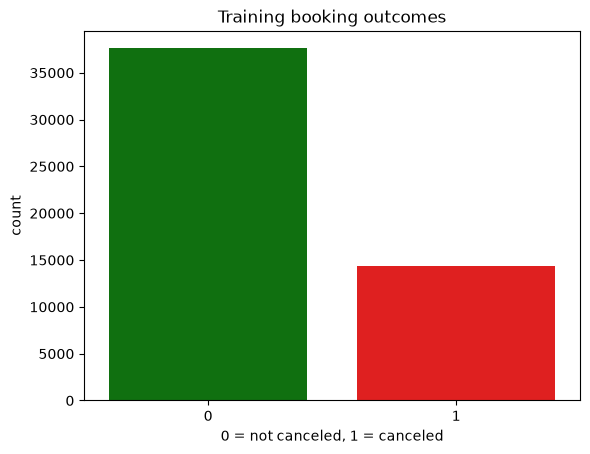

In [95]:
# Cancellation Counts
visuals = DataAnalyzer(processor.train_df)
visuals.plot_cancellation_counts()

Non-cancelled bookings are more common. I also check how many cancellations the models find, rather than using accuracy alone.

### Numerical Distributions
These charts show common values and unusually large values for four numerical inputs.

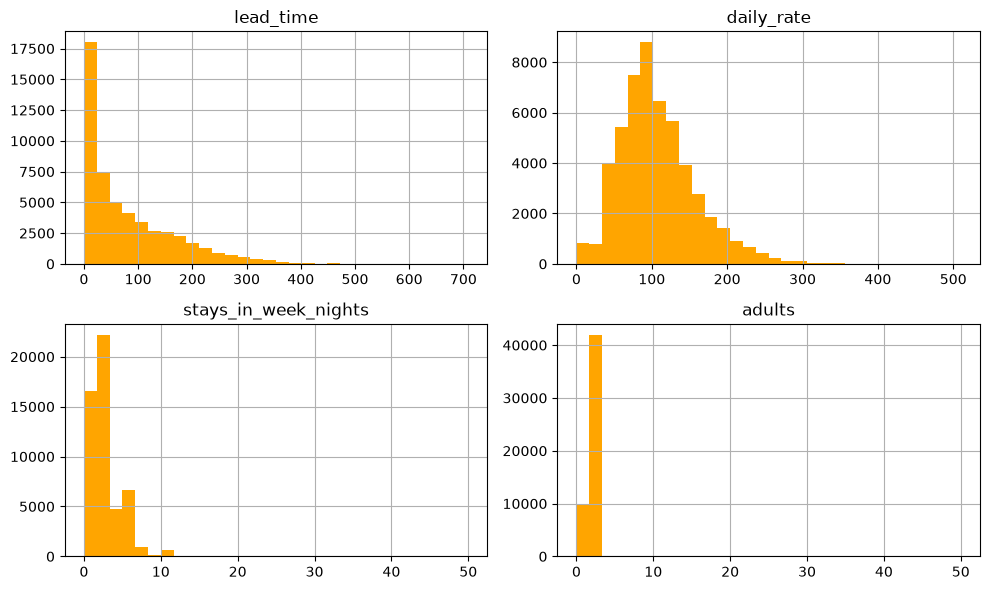

In [96]:
# Numerical Distributions
visuals.plot_distributions()

### Hotel Comparison
I compare the share of cancellations for each hotel type. The average of a 0-or-1 column gives this share.

,Not canceled,Canceled
hotel,,
City Hotel,0.697,0.303
Resort Hotel,0.765,0.235


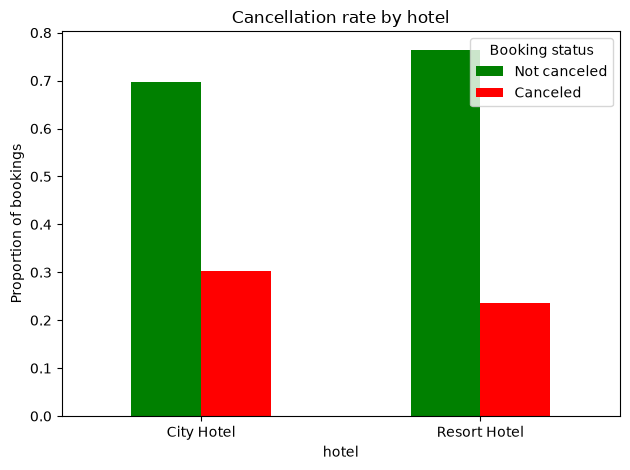

In [97]:
# Hotel Comparison
visuals.plot_hotel_rates()

About 30.3% of city-hotel bookings and 23.5% of resort-hotel bookings were cancelled in this training split. This does not explain the cause.

# Checking Unusual Values
I use boxplots to check unusual rates and lead times. I keep them because unusual does not always mean wrong.

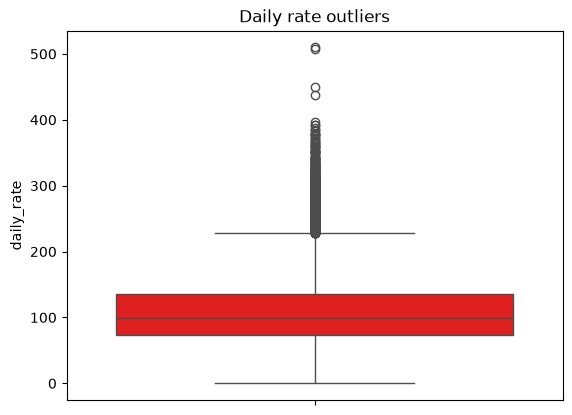

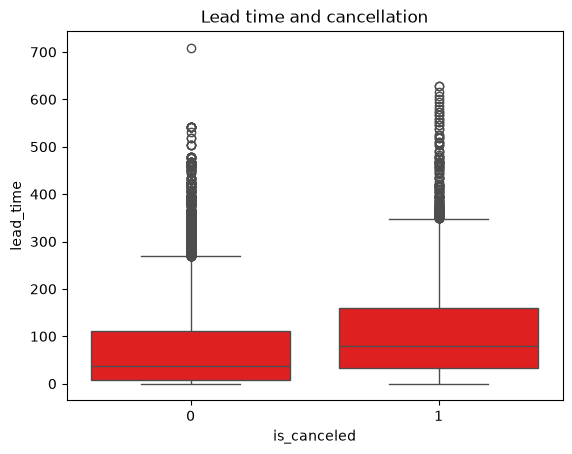

In [98]:
# Checking Unusual Values
visuals.plot_outliers()

## Feature Engineering
This method creates six extra columns. The next cells show examples of their calculations.

### Total Nights
Weekday nights plus weekend nights gives total nights.

In [99]:
# Total Nights
feature_analysis = DataAnalyzer(processor.add_features(processor.train_df))
feature_analysis.show_columns(["stays_in_weekend_nights", "stays_in_week_nights", "total_nights"])

,stays_in_weekend_nights,stays_in_week_nights,total_nights
70555,2,1,3
70235,1,2,3
7664,1,2,3
93795,2,1,3
62735,1,2,3


### Total Guests
Adults plus children plus babies gives total guests.

In [100]:
# Total Guests
feature_analysis.show_columns(["adults", "children", "babies", "total_guests"])

,adults,children,babies,total_guests
70555,2,1,0,3
70235,1,0,0,1
7664,3,1,0,4
93795,3,0,0,3
62735,1,0,0,1


### Children Indicator
This is 1 if children or babies are included, otherwise 0.

In [101]:
# Children Indicator
feature_analysis.show_columns(["children", "babies", "has_children"])

,children,babies,has_children
70555,1,0,1
70235,0,0,0
7664,1,0,1
93795,0,0,0
62735,0,0,0


### Weekend Share
Weekend nights divided by total nights gives the weekend share. Zero-night bookings were removed earlier.

In [102]:
# Weekend Share
feature_analysis.show_columns(["stays_in_weekend_nights", "total_nights", "weekend_share"])

,stays_in_weekend_nights,total_nights,weekend_share
70555,2,3,0.666667
70235,1,3,0.333333
7664,1,3,0.333333
93795,2,3,0.666667
62735,1,3,0.333333


### Previous Cancellation Rate
Previous cancellations divided by all previous bookings gives this rate. I use 0 for no history and keep the original counts too.

In [103]:
# Previous Cancellation Rate
feature_analysis.show_columns(["previous_cancellations", "previous_bookings_not_canceled", "previous_cancel_rate"])

,previous_cancellations,previous_bookings_not_canceled,previous_cancel_rate
70555,0,0,0.0
70235,0,0,0.0
7664,0,0,0.0
93795,0,0,0.0
62735,0,0,0.0


### Logarithmic Daily Rate
log1p makes large rate values smaller in scale and also allows zero rates.

,daily_rate,log_daily_rate
70555,135.0,4.912655
70235,135.0,4.912655
7664,274.0,5.616771
93795,152.4,5.033049
62735,85.2,4.456670


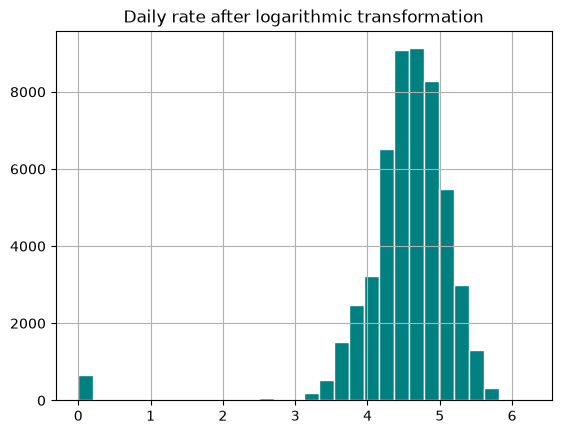

In [104]:
# Logarithmic Daily Rate
feature_analysis.plot_log_daily_rate()

## Correlation Analysis
Correlation shows whether numerical values tend to move together. It does not prove that one causes the other.

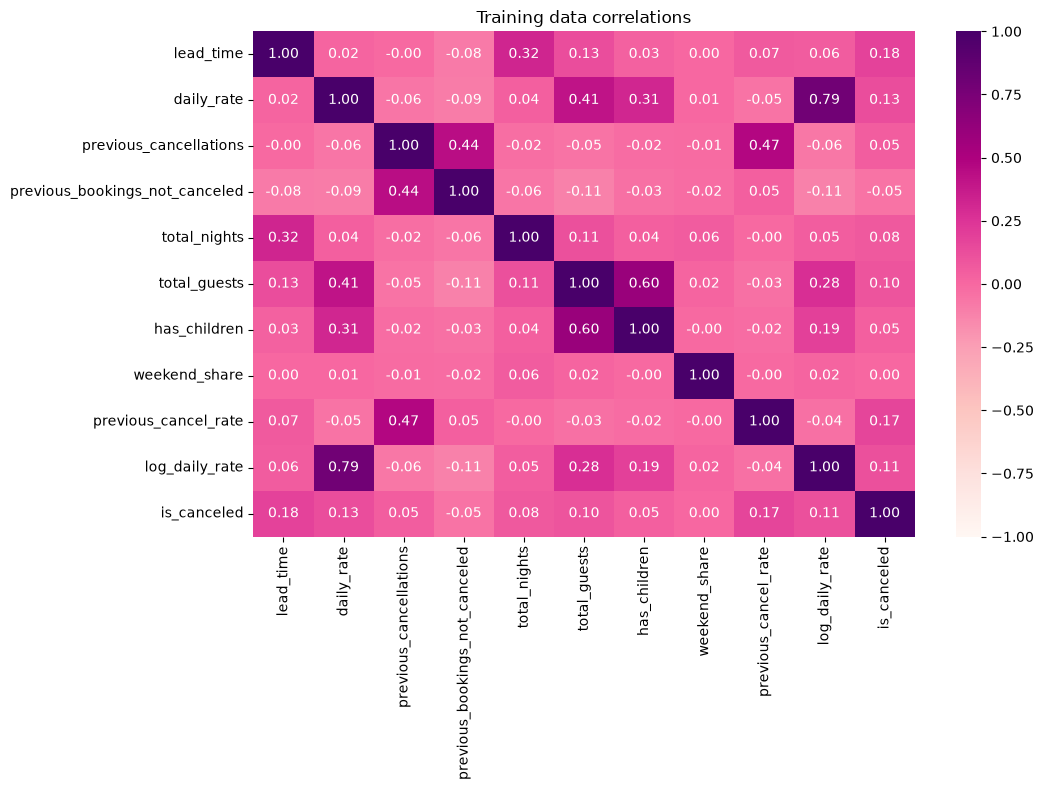

previous_bookings_not_canceled   -0.053031
weekend_share                     0.003210
has_children                      0.046523
previous_cancellations            0.046982
total_nights                      0.075705
total_guests                      0.098771
log_daily_rate                    0.112344
daily_rate                        0.127847
previous_cancel_rate              0.167413
lead_time                         0.183907
is_canceled                       1.000000
Name: is_canceled, dtype: float64

In [105]:
# Correlation Analysis
feature_analysis.plot_correlations()

Lead time and previous cancellation rate have small positive correlations with cancellation. Weekend share is close to zero, but may still help a model.

# Feature Selection
I compare the original inputs with those inputs plus six new columns to see whether they help.

## Encoding and Scaling
I turn categories into 0-or-1 columns and match the column order. Scaling is learned from training data only.

In [106]:
# Encoding and Scaling
processor.prepare_validation("Original")

Training input shape: (51980, 215)
Validation input shape: (17327, 215)


,lead_time,arrival_date_year,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,...,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
70555,137,2017,2,1,2,1,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
70235,128,2017,1,2,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
7664,59,2016,1,2,3,1,0,0,0,0,...,0,1,0,1,0,0,0,0,1,0
93795,169,2016,2,1,3,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
62735,164,2017,1,2,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0


## Model Builder Class
This class trains models and stores their scores. It keeps the model with the highest validation accuracy; ties keep the earlier model.

In [107]:
# Model Builder Class
class ModelBuilder:
    # Start an empty results list and track the best score.
    def __init__(self):
        self.results = []
        self.best_accuracy = -1

    # Train a model, save its scores and keep the best one.
    def train_model(self, name, model, train_x, validation_x, train_y, validation_y,
                    version, scaled=False, uses_pipeline=False):
        model.fit(train_x, train_y)
        predictions = model.predict(validation_x)
        accuracy = accuracy_score(validation_y, predictions)
        self.results.append({"Features": version, "Model": name,
                             "Training accuracy": model.score(train_x, train_y),
                             "Validation accuracy": accuracy,
                             "Precision": precision_score(validation_y, predictions, zero_division=0),
                             "Recall": recall_score(validation_y, predictions, zero_division=0),
                             "F1": f1_score(validation_y, predictions, zero_division=0)})
        print(name, version, "validation accuracy:", round(accuracy, 4))
        if accuracy > self.best_accuracy:
            self.best_accuracy = accuracy
            self.best_model = model
            self.best_name = name
            self.best_version = version
            self.best_scaled = scaled
            self.uses_pipeline = uses_pipeline

    # Train the chosen model again and check its test predictions.
    def evaluate_test(self, model, train_x, test_x, train_y, test_y):
        model.fit(train_x, train_y)
        self.predictions = model.predict(test_x)
        self.test_results = pd.DataFrame({
            "Model": [self.best_name],
            "Training accuracy": [model.score(train_x, train_y)],
            "Test accuracy": [accuracy_score(test_y, self.predictions)],
            "Precision": [precision_score(test_y, self.predictions, zero_division=0)],
            "Recall": [recall_score(test_y, self.predictions, zero_division=0)],
            "F1": [f1_score(test_y, self.predictions, zero_division=0)]})
        display(self.test_results.round(4))
        print(classification_report(test_y, self.predictions, labels=[0, 1],
                                    target_names=["Not canceled", "Canceled"], zero_division=0))
        self.confusion = confusion_matrix(test_y, self.predictions, labels=[0, 1])
        sns.heatmap(self.confusion, annot=True, fmt="d", cmap="Greens",
                    xticklabels=["Not canceled", "Canceled"], yticklabels=["Not canceled", "Canceled"])
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title("Final test confusion matrix")
        plt.tight_layout()
        plt.savefig("confusion_matrix.png", dpi=150)
        plt.show()

    # Check the score from always predicting the most common outcome.
    def show_baseline(self, processor):
        majority_class = processor.y_train.mode()[0]
        print("Majority class:", majority_class)
        print("Validation baseline accuracy:", round((processor.y_validation == majority_class).mean(), 4))

    # Try four Random Forest settings using training data.
    def tune_model(self, processor):
        train_new = processor.select_inputs(processor.train_df, "Engineered")
        category_columns = train_new.select_dtypes(exclude="number").columns.tolist()
        tuning_encoder = ColumnTransformer(
            [("categories", OneHotEncoder(handle_unknown="ignore"), category_columns)],
            remainder="passthrough")
        tuning_pipeline = Pipeline([
            ("encoding", tuning_encoder),
            ("model", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1))
        ])
        parameter_grid = {"model__max_depth": [10, None], "model__min_samples_leaf": [2, 5]}
        self.search = GridSearchCV(tuning_pipeline, parameter_grid, cv=3, scoring="accuracy", n_jobs=2)
        self.search.fit(train_new, processor.y_train)
        print("Best parameters:", self.search.best_params_)
        print("Best cross-validation accuracy:", round(self.search.best_score_, 4))
        display(pd.DataFrame(self.search.cv_results_)[["params", "mean_test_score", "std_test_score"]])

    # Check the tuned model on validation data.
    def validate_tuned(self, processor):
        train_new = processor.select_inputs(processor.train_df, "Engineered")
        validation_new = processor.select_inputs(processor.validation_df, "Engineered")
        self.train_model("Tuned Random Forest", self.search.best_estimator_, train_new, validation_new,
                         processor.y_train, processor.y_validation, "Engineered", uses_pipeline=True)

    # Show the scores and compare accuracy before and after adding features.
    def compare_models(self):
        self.validation_results = pd.DataFrame(self.results)
        display(self.validation_results.round(4))
        comparison = self.validation_results[self.validation_results["Model"] != "Tuned Random Forest"].pivot(
            index="Model", columns="Features", values=["Validation accuracy", "F1"])
        display(comparison.round(4))
        comparison["Validation accuracy"].plot(kind="bar", color=["black", "lightgray"], figsize=(9, 4))
        plt.ylabel("Validation accuracy")
        plt.ylim(0, 1)
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()
        print("Selected model:", self.best_name)
        print("Selected inputs:", self.best_version)

    # Prepare the chosen model's inputs and run the final test.
    def run_final_test(self, processor):
        development_inputs = processor.select_inputs(processor.development_df, self.best_version)
        test_inputs = processor.select_inputs(processor.test_df, self.best_version)

        # The tuned pipeline handles encoding itself.
        if not self.uses_pipeline:
            processor.encode_data(development_inputs, test_inputs)

        if self.uses_pipeline:
            final_train_x = development_inputs
            final_test_x = test_inputs
        elif self.best_scaled:
            final_train_x = processor.train_scaled
            final_test_x = processor.check_scaled
        else:
            final_train_x = processor.train_encoded
            final_test_x = processor.check_encoded

        test_majority = processor.development_df["is_canceled"].mode()[0]
        self.test_baseline = (processor.test_df["is_canceled"] == test_majority).mean()
        print("Test majority baseline accuracy:", round(self.test_baseline, 4))
        self.evaluate_test(self.best_model, final_train_x, final_test_x,
                             processor.development_df["is_canceled"], processor.test_df["is_canceled"])

    # Save the model scores as CSV files.
    def save_results(self):
        self.validation_results.to_csv("validation_results.csv", index=False)
        self.test_results.to_csv("test_results.csv", index=False)
        print("Model results saved as CSV files.")

## Majority Baseline
This always predicts the most common training outcome. It gives a simple score to compare against.

In [108]:
# Majority Baseline
models = ModelBuilder()
models.show_baseline(processor)

Majority class: 0
Validation baseline accuracy: 0.7231


## Logistic Regression
Logistic Regression combines the inputs to predict cancellation. I use scaled numerical values.

In [109]:
# Logistic Regression
models.train_model("Logistic Regression", LogisticRegression(max_iter=2000),
                   processor.train_scaled, processor.check_scaled, processor.y_train, processor.y_validation,
                   "Original", scaled=True)

Logistic Regression Original validation accuracy: 0.7578


## Decision Tree
The tree makes predictions through questions about the inputs. I limit its depth to 6.

In [110]:
# Decision Tree
models.train_model("Decision Tree", DecisionTreeClassifier(max_depth=6, random_state=42),
                   processor.train_encoded, processor.check_encoded, processor.y_train, processor.y_validation, "Original")

Decision Tree Original validation accuracy: 0.7584


## Random Forest
This combines 100 trees. Each final branch needs at least five training records.

In [111]:
# Random Forest
models.train_model("Random Forest", RandomForestClassifier(
    n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1),
    processor.train_encoded, processor.check_encoded, processor.y_train, processor.y_validation, "Original")

Random Forest Original validation accuracy: 0.7772


## K Nearest Neighbours
KNN predicts using the five closest training bookings. Scaling helps keep larger numbers from dominating the distance.

In [112]:
# K Nearest Neighbours
models.train_model("KNN", KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
                   processor.train_scaled, processor.check_scaled, processor.y_train, processor.y_validation,
                   "Original", scaled=True)

KNN Original validation accuracy: 0.748


## Models with Engineered Features
I repeat the models with the same records and settings, adding the six new columns.

In [113]:
# Models with Engineered Features
processor.prepare_validation("Engineered")

Training input shape: (51980, 221)
Validation input shape: (17327, 221)


,lead_time,arrival_date_year,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,...,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
70555,137,2017,2,1,2,1,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
70235,128,2017,1,2,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
7664,59,2016,1,2,3,1,0,0,0,0,...,0,1,0,1,0,0,0,0,1,0
93795,169,2016,2,1,3,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
62735,164,2017,1,2,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0


In [114]:
# Models with Engineered Features
models.train_model("Logistic Regression", LogisticRegression(max_iter=2000),
                   processor.train_scaled, processor.check_scaled, processor.y_train, processor.y_validation,
                   "Engineered", scaled=True)
models.train_model("Decision Tree", DecisionTreeClassifier(max_depth=6, random_state=42),
                   processor.train_encoded, processor.check_encoded, processor.y_train, processor.y_validation, "Engineered")
models.train_model("Random Forest", RandomForestClassifier(
    n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1),
    processor.train_encoded, processor.check_encoded, processor.y_train, processor.y_validation, "Engineered")

Logistic Regression Engineered validation accuracy: 0.7605
Decision Tree Engineered validation accuracy: 0.7584
Random Forest Engineered validation accuracy: 0.7781


### KNN with Engineered Features
I use the same five-neighbour setting and validation records, now with the extra columns.

In [115]:
# KNN with Engineered Features
models.train_model("KNN", KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
                   processor.train_scaled, processor.check_scaled, processor.y_train, processor.y_validation,
                   "Engineered", scaled=True)

KNN Engineered validation accuracy: 0.7447


## Hyperparameter Tuning
I test four Random Forest settings using three parts of the training data. Encoding is learned within each round; validation and test data are kept separate.

In [116]:
# Hyperparameter Tuning
models.tune_model(processor)

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2}
Best cross-validation accuracy: 0.786


,params,mean_test_score,std_test_score
0,"{'model__max_depth': 10, 'model__min_samples_l...",0.748673,0.003653
1,"{'model__max_depth': 10, 'model__min_samples_l...",0.747114,0.001679
2,"{'model__max_depth': None, 'model__min_samples...",0.785975,0.002881
3,"{'model__max_depth': None, 'model__min_samples...",0.777087,0.003041


## Tuned Model Validation
I compare the tuned model with the others on validation data. It is selected only if its accuracy is higher.

In [ ]:
# Tuned Model Validation
models.validate_tuned(processor)

## Model Comparison
Accuracy counts all correct predictions. Precision checks cancellation alerts, recall checks cancellations found, and F1 combines both. A much higher training score can suggest overfitting.

,Features,Model,Training accuracy,Validation accuracy,Precision,Recall,F1
0,Original,Logistic Regression,0.7620,0.7578,0.6190,0.3252,0.4264
1,Original,Decision Tree,0.7577,0.7584,0.6439,0.2850,0.3951
2,Original,Random Forest,0.8035,0.7772,0.7580,0.2866,0.4160
3,Original,KNN,0.8326,0.7480,0.5555,0.4499,0.4971
4,Engineered,Logistic Regression,0.7644,0.7605,0.6279,0.3310,0.4335
5,Engineered,Decision Tree,0.7574,0.7584,0.6437,0.2848,0.3949
6,Engineered,Random Forest,0.8124,0.7781,0.7630,0.2879,0.4180
7,Engineered,KNN,0.8310,0.7447,0.5480,0.4438,0.4904
8,Engineered,Tuned Random Forest,0.8882,0.7870,0.7232,0.3736,0.4926


Validation accuracy                  F1         
Features                     Engineered Original Engineered Original
Model                                                               
Decision Tree                    0.7584   0.7584     0.3949   0.3951
KNN                              0.7447   0.7480     0.4904   0.4971
Logistic Regression              0.7605   0.7578     0.4335   0.4264
Random Forest                    0.7781   0.7772     0.4180   0.4160

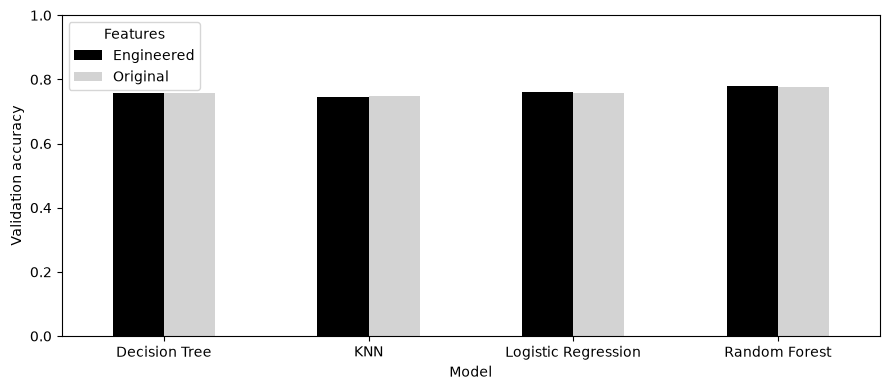

Selected model: Tuned Random Forest
Selected inputs: Engineered


In [ ]:
# Model Comparison
models.compare_models()

## Final Test Evaluation
I train the selected model on training and validation data together, then check it on the separate test data.

Test majority baseline accuracy: 0.7232


,Model,Training accuracy,Test accuracy,Precision,Recall,F1
0,Tuned Random Forest,0.8905,0.7953,0.7322,0.4106,0.5261


              precision    recall  f1-score   support

Not canceled       0.81      0.94      0.87     12531
    Canceled       0.73      0.41      0.53      4796

    accuracy                           0.80     17327
   macro avg       0.77      0.68      0.70     17327
weighted avg       0.79      0.80      0.77     17327



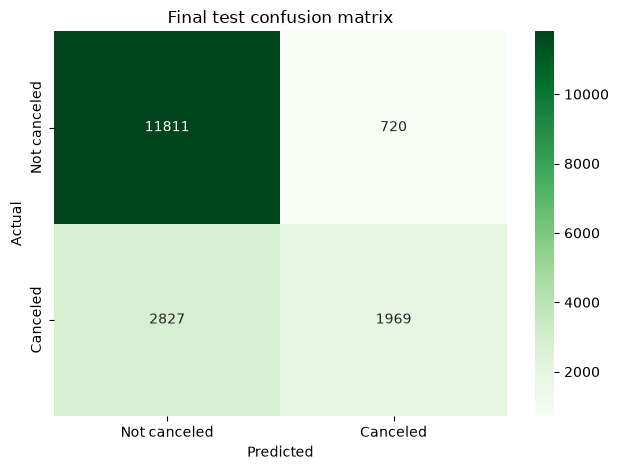

In [ ]:
# Final Test Evaluation
models.run_final_test(processor)

The model made 720 false alerts and missed 2,827 cancellations. It correctly predicted 11,811 non-cancellations and 1,969 cancellations.

## Reading the Confusion Matrix
Rows show actual outcomes and columns show predictions. Top right means false alerts; bottom left means missed cancellations.

## Unsupervised Learning Class
K-Means groups similar bookings using four inputs. It does not use cancellation labels to form the groups.

In [ ]:
# Unsupervised Learning Class
class BookingClusters:
    # Store the starting data and settings for this object.
    def __init__(self, train_table, check_table):
        self.columns = ["lead_time", "log_daily_rate", "total_nights", "total_guests"]
        self.train_table = train_table
        self.check_table = check_table
        self.scaler = StandardScaler()
        self.train_scaled = self.scaler.fit_transform(train_table[self.columns])
        self.check_scaled = self.scaler.transform(check_table[self.columns])

    # Compare two to five booking groups using a fixed sample.
    def compare_groups(self):
        # A fixed sample keeps the elbow and silhouette calculations manageable.
        sample = pd.DataFrame(self.train_scaled).sample(
            n=min(2000, len(self.train_scaled)), random_state=42)
        results = []
        for k in range(2, 6):
            model = KMeans(n_clusters=k, n_init=10, random_state=42)
            labels = model.fit_predict(sample)
            score = silhouette_score(sample, labels, sample_size=min(1000, len(sample)), random_state=42)
            results.append({"Clusters": k, "Inertia": model.inertia_, "Silhouette": score})
        self.comparison = pd.DataFrame(results)
        display(self.comparison.round(3))
        self.best_k = int(self.comparison.loc[self.comparison["Silhouette"].idxmax(), "Clusters"])
        self.comparison.plot(x="Clusters", y="Inertia", marker="o", color="gray")
        plt.title("Elbow method on training sample")
        plt.show()
        self.comparison.plot(x="Clusters", y="Silhouette", marker="o", color="gray")
        plt.title("Silhouette score on training sample")
        plt.show()
        print("Selected cluster count:", self.best_k)

    # Form booking groups, then inspect their details and cancellation rates.
    def fit_groups(self):
        self.model = KMeans(n_clusters=self.best_k, n_init=10, random_state=42)
        self.model.fit(self.train_scaled)
        self.results = self.check_table[["lead_time", "daily_rate", "total_nights", "total_guests"]].copy()
        self.results["cluster"] = self.model.predict(self.check_scaled)
        display(self.results.groupby("cluster").agg(
            bookings=("lead_time", "size"), lead_time=("lead_time", "mean"),
            daily_rate=("daily_rate", "mean"), total_nights=("total_nights", "mean"),
            total_guests=("total_guests", "mean")).round(2))
        sample = self.results.sample(n=min(1500, len(self.results)), random_state=42)
        sns.scatterplot(data=sample, x="lead_time", y="total_nights", hue="cluster", palette="Purples", alpha=0.5)
        plt.title("Booking groups shown in two dimensions")
        plt.show()
        # Outcome rates are inspected only after fitting the clusters.
        self.results["is_canceled"] = self.check_table["is_canceled"]
        self.rates = self.results.groupby("cluster")["is_canceled"].agg(["count", "mean"])
        display(self.rates.round(3))

    # Save the results as CSV files.
    def save_results(self):
        self.results.groupby("cluster").mean().to_csv("cluster_summary.csv")
        self.rates.to_csv("cluster_cancellation_rates.csv")
        print("Cluster results saved as CSV files.")

## Selecting the Number of Groups
I compare two to five groups on a sample. The elbow chart shows group distances, and a higher silhouette score means clearer separation.

,Clusters,Inertia,Silhouette
0,2,6121.649,0.286
1,3,4942.641,0.331
2,4,3875.063,0.354
3,5,3267.096,0.346


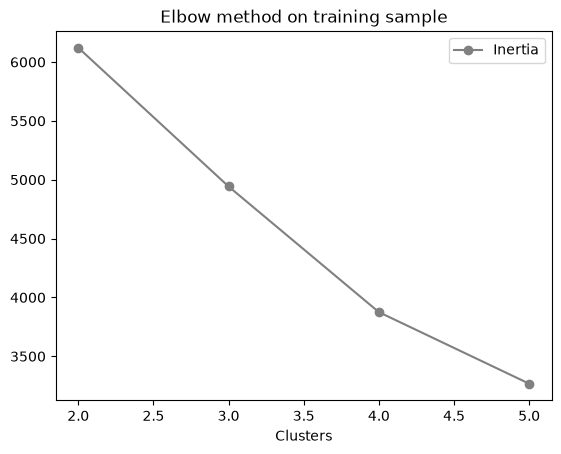

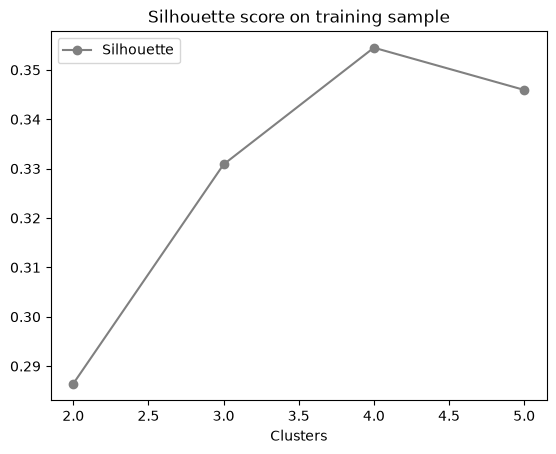

Selected cluster count: 4


In [ ]:
# Selecting the Number of Groups
clusters = BookingClusters(processor.add_features(processor.development_df),
                           processor.add_features(processor.test_df))
clusters.compare_groups()

Four groups gave the highest sampled score, about 0.35. This is the best option tested, not a guaranteed perfect choice.

## Exploring the Groups
I compare group sizes, average booking details and cancellation rates. The chart shows only two of the four inputs.

,bookings,lead_time,daily_rate,total_nights,total_guests
cluster,,,,,
0,10279,37.32,98.48,2.70,1.75
1,2503,74.36,162.30,3.51,3.37
2,239,42.32,0.87,2.49,1.65
3,4306,188.19,100.83,6.06,1.97


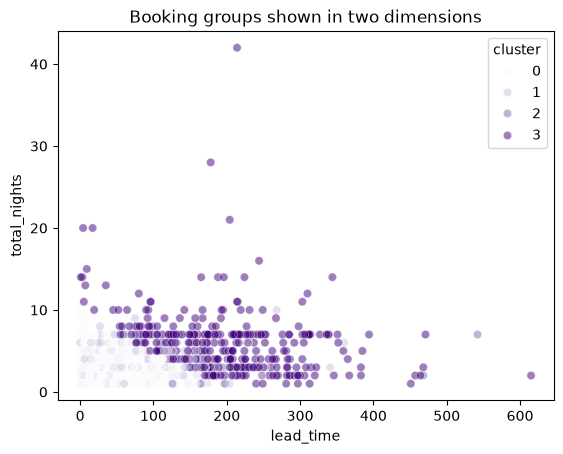

,count,mean
cluster,,
0,10279,0.228
1,2503,0.335
2,239,0.155
3,4306,0.367


In [ ]:
# Exploring the Groups
clusters.fit_groups()

Group 0 books closer to arrival. Group 1 has larger parties and higher rates. Group 2 has very low rates and only 239 bookings. Group 3 books earlier and stays longer. Small groups may give less stable rates.

## Saving Results
I save the scores and group summaries as CSV files. These and the saved charts can be downloaded from the notebook folder.

In [ ]:
# Saving Results
models.save_results()
clusters.save_results()

Model results saved as CSV files.
Cluster results saved as CSV files.


## Results and Conclusion
Tuned Random Forest scored 79.53% test accuracy, compared with the 72.32% baseline. Its higher training score of 89.05% suggests some overfitting.

The extra columns helped some models slightly, but not all. Tuning gave 78.70% validation accuracy.

The final model found only 41.1% of cancellations, so accuracy alone is not enough. K-Means found four groups with cancellation rates from 15.5% to 36.7%.

## Program Design
I use five classes for loading, analysis, preparation, modelling and grouping bookings. Objects store the data, and methods carry out the tasks. The other cells create objects and call their methods.

## Limitations
There are a few limits to my results. I used older bookings and one random split, so the scores could change with different data. Bookings made together might also end up in both training and testing.

I assumed the input details were known when making the prediction. I also removed identical rows, although some might have been separate real bookings.

So, these results show how the model worked on this test data. They do not mean it will always get the same score on future bookings.

# References
Mostipak, J. (n.d.) Hotel booking demand. Kaggle. Available at: https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

Original dataset publication: Antonio, N., de Almeida, A. and Nunes, L. (2019) Hotel booking demand datasets. Data in Brief, 22, pp. 41–49. https://doi.org/10.1016/j.dib.2018.11.126